# **Analysis of the Impact of Bitcoin Reserves on a Company's Balance Sheet on Its Stock Performance, Through Correlation and Cointegration Analysis Using Techniques from Statistical Arbitrage**

MicroStrategy is a tech company operating in the mobile software and cloud services sector. Founded in 1989, it gained prominence for its **strategy of accumulating Bitcoin as a reserve** on its balance sheet starting in August 2020, reaching a holding of approximately 424,000 BTC by the end of last year.

An innovative choice, but **not without risks**: from market volatility to the increased risk due to leverage, which could have disruptive effects in the event of a sharp and significant drop in the value of Bitcoin.

METHOD

The analysis was based on two fundamental statistical approaches to assess the relationship between the price of Bitcoin and the value of MicroStrategy stock:

* **Pearson Correlation**: to measure the strength and direction of the short-term linear relationship between the closing prices of the two assets, supported by the calculation of the p-value for statistical significance.

* **Cointegration test with ADF on the residuals of an OLS regression**: to assess whether a long-term equilibrium exists between the two assets, i.e., whether their time series share a stable relationship that binds them over time, despite fluctuations due to short-term market sentiment and factors.

These tools are widely used in **statistical arbitrage** and **financial risk management** to identify opportunities and structural correlations.

SUMMARY

The analysis confirms a strong short-term relationship between Bitcoin and MicroStrategy, accompanied by stable long-term cointegration. This indicates a structural link that can be leveraged for risk management and financial optimization strategies.

In [ ]:
# General libraries
import pandas as pd
import numpy as np
import yfinance as yf
from datetime import datetime, timedelta

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Hypothesis testing
from statsmodels.tsa.stattools import adfuller

* Time: one-year observation period with daily interval
* Required columns: Open, High, Low, Close, and Volume.

In [ ]:
from datetime import datetime, timedelta
import yfinance as yf

# Define the time window over the past year
end_time = datetime.now()
start_time = end_time - timedelta(days=1 * 365)

# Format the dates for import
start_date = start_time.strftime('%Y-%m-%d')
end_date = end_time.strftime('%Y-%m-%d')

# --- Bitcoin (BTC-USD) ---
try:
    btc_data = yf.download(tickers='BTC-USD', start=start_date, end=end_date, interval='1d')
    if btc_data.empty:
        print("No data available for Bitcoin (BTC-USD) in the specified period.")
    else:
        # Access Bitcoin data with 'btc_data'
        print("\nBitcoin (BTC-USD) data:")
        print(btc_data[['Open', 'High', 'Low', 'Close', 'Volume']])

        # Save the data to a CSV file, checking 'Date' index
        btc_data[['Open', 'High', 'Low', 'Close', 'Volume']].to_csv('btc_data.csv', index=True)
        print("\nBitcoin data saved to 'btc_data.csv'")
except Exception as e:
    print(f"Error downloading data for Bitcoin (BTC-USD): {e}")


YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


Bitcoin (BTC-USD) data:
Price                Open           High            Low          Close  \
Ticker            BTC-USD        BTC-USD        BTC-USD        BTC-USD   
Date                                                                     
2024-05-29   68296.351562   68852.460938   67101.492188   67578.093750   
2024-05-30   67576.085938   69500.539062   67118.078125   68364.992188   
2024-05-31   68362.515625   68999.562500   66633.421875   67491.414062   
2024-06-01   67489.609375   67839.765625   67386.195312   67706.937500   
2024-06-02   67710.273438   68409.164062   67315.523438   67751.601562   
...                   ...            ...            ...            ...   
2025-05-24  107278.507812  109454.523438  106895.289062  107791.156250   
2025-05-25  107802.273438  109313.304688  106683.375000  109035.390625   
2025-05-26  109023.781250  110376.882812  108735.640625  109440.367188   
2025-05-27  109440.406250  110744.210938  107609.554688  108994.640625   
2025-05-28  1

In [ ]:
# Load the CSV file, ignoring unnecessary rows and treating 'Date' as a datetime index
btc_data_saved = pd.read_csv('btc_data.csv', header=2, index_col=0, parse_dates=True)

# Rename the columns so they are correct
btc_data_saved.columns = ['Open', 'High', 'Low', 'Close', 'Volume']

# Remove any empty rows or rows with NaN values
btc_data_saved.dropna(inplace=True)

# Check the first rows
print("\nFirst rows Bitcoin:")
print(btc_data_saved.head())

# Save the cleaned DataFrame to a new CSV file
btc_data_saved.to_csv('btc_data_cleaned.csv')


First rows Bitcoin:
                    Open          High           Low         Close  \
Date                                                                 
2024-05-29  68296.351562  68852.460938  67101.492188  67578.093750   
2024-05-30  67576.085938  69500.539062  67118.078125  68364.992188   
2024-05-31  68362.515625  68999.562500  66633.421875  67491.414062   
2024-06-01  67489.609375  67839.765625  67386.195312  67706.937500   
2024-06-02  67710.273438  68409.164062  67315.523438  67751.601562   

                 Volume  
Date                     
2024-05-29  26707072906  
2024-05-30  29509712534  
2024-05-31  27387283769  
2024-06-01  11641495604  
2024-06-02  17110588415  


In [ ]:
# --- mstr_data ---
try:
    # Ticker 'MSTR' for MicroStrategy
    mstr_data = yf.download(tickers='MSTR', start=start_date, end=end_date, interval='1d')

    # Check if data is available
    if mstr_data.empty:
        print("No data available for MicroStrategy (MSTR) in the specified period.")
    else:
        # Display data for MicroStrategy
        print("\nMicroStrategy (MSTR) data:")
        print(mstr_data[['Open', 'High', 'Low', 'Close', 'Volume']])

        # Save data to a CSV file, ensuring 'Date' is kept as index
        mstr_data[['Open', 'High', 'Low', 'Close', 'Volume']].to_csv('mstr_data.csv', index=True)

        # Confirmation message
        print("\nMicroStrategy data saved to 'mstr_data.csv'")
except Exception as e:
    print(f"Error downloading data for MicroStrategy (MSTR): {e}")


[*********************100%***********************]  1 of 1 completed


MicroStrategy (MSTR) data:
Price             Open        High         Low       Close    Volume
Ticker            MSTR        MSTR        MSTR        MSTR      MSTR
Date                                                                
2024-05-29  165.000000  165.906998  161.117996  161.869995   7344000
2024-05-30  165.300003  171.498993  153.195999  154.100006  14776000
2024-05-31  159.699997  161.481995  144.199997  152.449005  22154000
2024-06-03  160.100006  165.600006  156.042007  162.740997  11222000
2024-06-04  161.742004  169.699997  161.500000  163.876999  13230000
...                ...         ...         ...         ...       ...
2025-05-21  415.920013  423.339996  395.529999  402.690002  18698500
2025-05-22  413.200012  426.320007  398.910004  399.459991  16511400
2025-05-23  391.510010  392.190002  367.309998  369.510010  21448800
2025-05-27  381.119995  381.299988  364.179993  372.200012  14116000
2025-05-28  368.529999  370.649994  358.500000  364.250000   9844400

[250 

In [ ]:
# Load the CSV file, ignoring unnecessary rows and treating 'Date' as a datetime index
mstr_data_saved = pd.read_csv('mstr_data.csv', header=2, index_col=0, parse_dates=True)

# Check if the header is correct and rename the columns
mstr_data_saved.columns = ['Open', 'High', 'Low', 'Close', 'Volume']

# Remove any empty rows or rows with NaN values
mstr_data_saved.dropna(inplace=True)

# Check the first rows to see if the data is correctly read
print("\nFirst rows MicroStrategy:")
print(mstr_data_saved.head())

# Save the cleaned DataFrame to a new CSV file
mstr_data_saved.to_csv('mstr_data_cleaned.csv')

print("\nClean data saved as 'mstr_data_cleaned.csv'")


First rows MicroStrategy:
                  Open        High         Low       Close    Volume
Date                                                                
2024-05-29  165.000000  165.906998  161.117996  161.869995   7344000
2024-05-30  165.300003  171.498993  153.195999  154.100006  14776000
2024-05-31  159.699997  161.481995  144.199997  152.449005  22154000
2024-06-03  160.100006  165.600006  156.042007  162.740997  11222000
2024-06-04  161.742004  169.699997  161.500000  163.876999  13230000

Clean data saved as 'mstr_data_cleaned.csv'


We have the two time series associated with Bitcoin and MicroStrategy, which we imported into a CSV file so that we can check the data within a strict framework and not have to depend on requests to Yahoo Finance.

We collected data for the 5 performance columns, but we will primarily focus on "Close," that is, the asset’s price at the end of the day.

**EDA (EXPLORATORY DATA ANALYSIS)**

**Bitcoin**

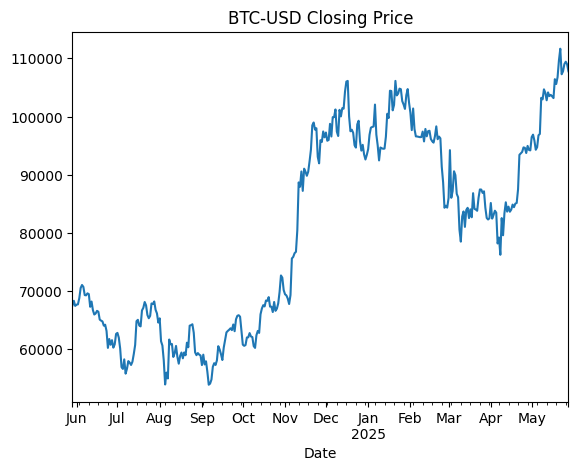

In [ ]:
# Load the cleaned data from the CSV
btc_data_saved = pd.read_csv('btc_data_cleaned.csv', index_col=0, parse_dates=True)

# Plot the closing price chart
_= btc_data_saved['Close'].plot(title='BTC-USD Closing Price')

Chart: Data from the last year June 2024 - June 2025

In [ ]:
btc_data_saved.shape

(365, 5)

In [ ]:
btc_data_saved.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 365 entries, 2024-05-29 to 2025-05-28
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    365 non-null    float64
 1   High    365 non-null    float64
 2   Low     365 non-null    float64
 3   Close   365 non-null    float64
 4   Volume  365 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 17.1 KB


MicroStrategy (MSTR)

Let's observe the historical performance of MicroStrategy.

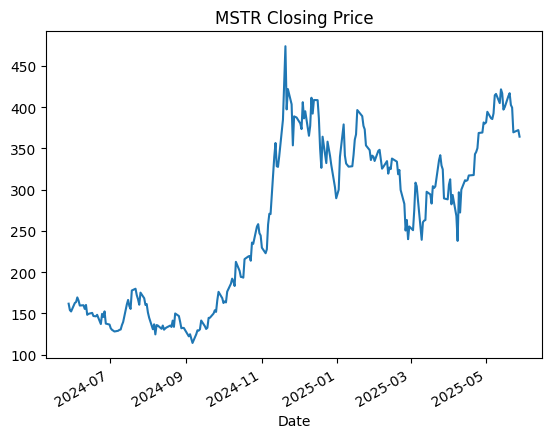

In [ ]:
# Load the data from the CSV file, ensuring that 'Date' is the index and dates are parsed correctly
mstr_data_saved = pd.read_csv('mstr_data_cleaned.csv', index_col=0, parse_dates=True)

# Plot the closing price chart
_= mstr_data_saved['Close'].plot(title='MSTR Closing Price')

Chart: Data from the last year June 2024 - June 2025

In [ ]:
mstr_data_saved.shape

(250, 5)

In [ ]:
mstr_data_saved.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 250 entries, 2024-05-29 to 2025-05-28
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    250 non-null    float64
 1   High    250 non-null    float64
 2   Low     250 non-null    float64
 3   Close   250 non-null    float64
 4   Volume  250 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.7 KB


We visually compare the performance of Bitcoin and MicroStrategy using the daily closing price (Close), applying a normalization technique that divides each series by its initial value (iloc\[0]), allowing us to compare the percentage trends even with different price scales.

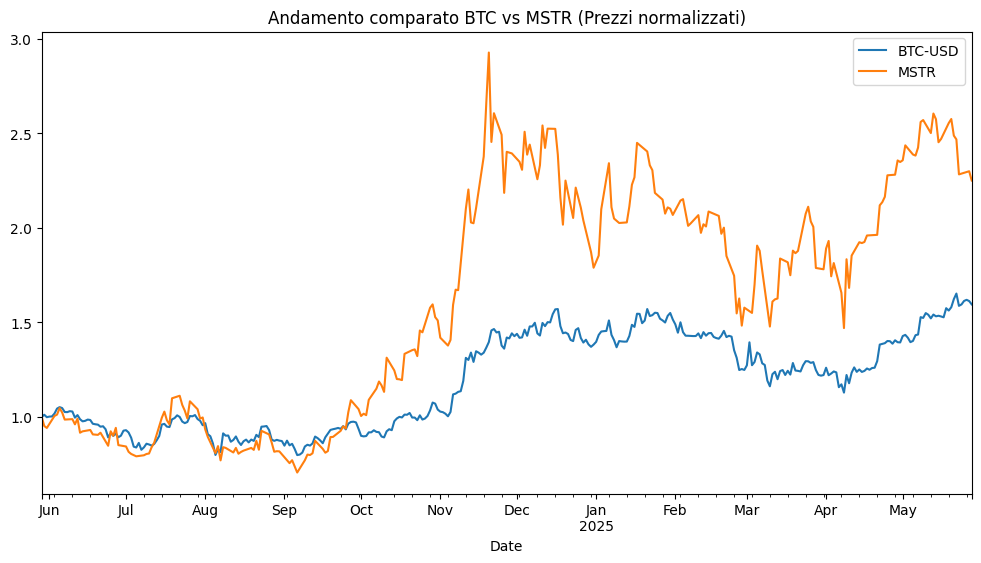

In [ ]:
# Grafico comparativo dei prezzi di chiusura normalizzati
(btc_data_saved['Close'] / btc_data_saved['Close'].iloc[0]).plot(label='BTC-USD', figsize=(12,6))
(mstr_data_saved['Close'] / mstr_data_saved['Close'].iloc[0]).plot(label='MSTR')
plt.title('Andamento comparato BTC vs MSTR (Prezzi normalizzati)')
plt.legend()
plt.show()

Chart: Data from the last year June 2024 - June 2025

At first glance, the two historical closing price series of the respective assets appear to be linked by a relationship that deserves further investigation through correlation and cointegration analysis.

**CORRELATION AND COINTEGRATION**

Correlation and cointegration are important statistical measures for analyzing the relationship between two time series.

**Correlation** quantifies the degree of **linear association between two time series**, revealing whether the two variables increase or decrease together and the strength of this relationship. The correlation coefficient ranges from -1 to 1. A coefficient of 1 indicates a perfect positive linear relationship, -1 represents a perfect negative linear relationship, while 0 suggests the absence of any linear relationship.

In contrast, **cointegration** concerns the **long-term equilibrium relationship between two potentially non-stationary time series**. If two time series are cointegrated, it means they share a common trend in the long run, regardless of short-term market-driven fluctuations. This allows analysts to identify **persistent relationships** that would otherwise be **hidden by transient market volatility**. Two series can thus be linked in the short term without having a stable long-term relationship, showing they move together in the short term without a binding long-term relationship forcing them to reconverge, or they can exhibit a cointegration constraint even though prices struggle to converge in the short term due to market factors with short-term effects. It is therefore important to assess both aspects when evaluating the association between two assets.

For example:

* The prices of Bitcoin and Nvidia tend to be correlated because both assets are influenced by enthusiasm for cryptocurrencies and demand for mining hardware.
* However, the two assets may not be cointegrated, because in the long run their price dynamics may follow completely different economic forces: Bitcoin may be influenced by regulations, adoption, and global liquidity, while Nvidia may be tied to the tech sector, chip sales, and production cycles.

PEARSON CORRELATION

In [ ]:
common = pd.concat([btc_data_saved['Close'], mstr_data_saved['Close']], axis=1, join='inner')

from scipy.stats import pearsonr
corr, pval = pearsonr(common.iloc[:,0], common.iloc[:,1])
print(f"Pearson Correlation: {corr:.4f} | P-value: {pval:.4e}")


Pearson Correlation: 0.9579 | P-value: 1.9630e-136


**Pearson Correlation: 0.9579**

A value very close to 1: this indicates a strong positive linear correlation between the closing prices of Bitcoin and MicroStrategy. So when Bitcoin goes up or down, the MSTR stock tends to do the same.

**P-value: 1.96e-136** (i.e., 0.000…0000196 with 136 zeros)

Much smaller than 0.05: the observed correlation is statistically significant. This means it is extremely unlikely that such a high correlation is due to chance.

**CONCLUSIONS**

MicroStrategy and Bitcoin have a strong and significant correlation over the analyzed period. This supports the hypothesis that MicroStrategy’s stock performance is strongly tied to its exposure to Bitcoin.

We represent the correlation visually through:

* Calculation of differenced logarithmic returns.

* Alignment of the time series.

* Calculation of variance and correlation.

* Visualization with a regression plot.

Bitcoin returns variance: 0.0007958082790307325
MicroStrategy returns variance: 0.003701379910414921
Correlation between differenced logarithmic returns of Bitcoin and MicroStrategy: 0.6419387822052807


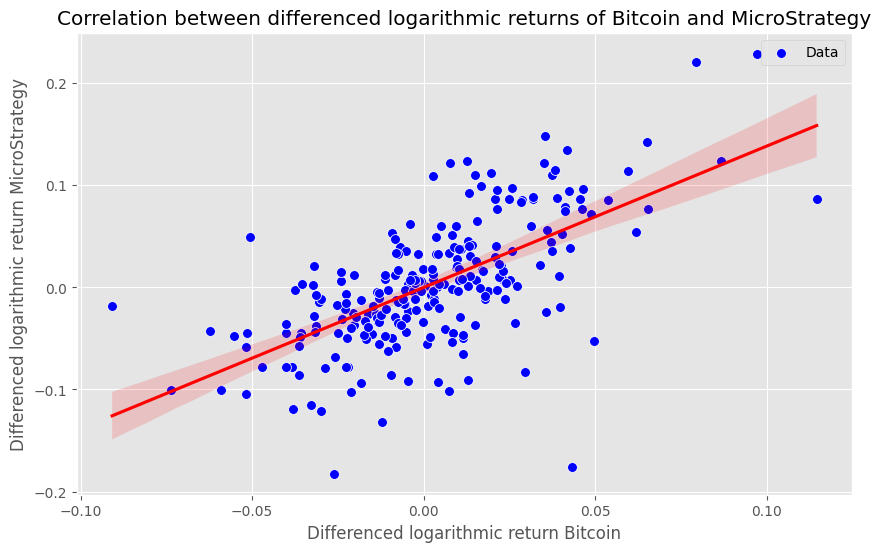

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculation of differenced logarithmic returns
btc_data_saved['Close_log_diff'] = np.log(btc_data_saved['Close']).diff()
mstr_data_saved['Close_log_diff'] = np.log(mstr_data_saved['Close']).diff()

# Merge the two DataFrames on dates
data = pd.merge(
    btc_data_saved[['Close_log_diff']],
    mstr_data_saved[['Close_log_diff']],
    left_index=True,
    right_index=True,
    suffixes=('_Bitcoin', '_MicroStrategy')
).dropna()

# Rename the columns
data.rename(columns={
    'Close_log_diff_Bitcoin': 'Bitcoin',
    'Close_log_diff_MicroStrategy': 'MicroStrategy'
}, inplace=True)

# Calculate variance and correlation
btc_var = data['Bitcoin'].var()
mstr_var = data['MicroStrategy'].var()
correlation = data['Bitcoin'].corr(data['MicroStrategy'])

# Print results
print(f"Bitcoin returns variance: {btc_var}")
print(f"MicroStrategy returns variance: {mstr_var}")
print(f"Correlation between differenced logarithmic returns of Bitcoin and MicroStrategy: {correlation}")

# Plot visualization
plt.style.use('ggplot')
plt.figure(figsize=(10, 6))

sns.scatterplot(x='Bitcoin', y='MicroStrategy', data=data, color='blue', label='Data', s=50)
sns.regplot(x='Bitcoin', y='MicroStrategy', data=data, scatter=False, line_kws={'color': 'red'})

plt.title('Correlation between differenced logarithmic returns of Bitcoin and MicroStrategy')
plt.xlabel('Differenced logarithmic return Bitcoin')
plt.ylabel('Differenced logarithmic return MicroStrategy')
plt.legend()
plt.show()


We therefore also analyze its long-term component through a cointegration analysis.

COINTEGRATION ANALYSIS USING PAIRS TRADING TECHNIQUES

**Pairs trading** is a market-neutral strategy that uses statistical analysis to relate two historical price series. This allows for potential profits regardless of market direction and short-term fluctuations caused by factors such as sentiment, sudden news, or unforeseen events, which result in a temporary divergence in price relationship.

Statistical arbitrage and pairs trading are usually used by traders to **take advantage of price movements**. In fact, if two assets are cointegrated, their prices maintain a stable equilibrium, and any spread that arises due to short-term and contextual factors tends to revert over time.
A trader might apply a pairs trading strategy by buying the undervalued asset and selling the overvalued one to profit from the reversion of the spread in the long run.

The **cointegration test** is useful to determine whether a linear combination of the prices of two assets produces a **stationary time series**, even when each individual series is not.
In other words, the historical differences (or the spread) between two cointegrated assets form a stationary series. This allows one to monitor the current spread and evaluate whether it significantly deviates from the historical one, suggesting potential trading opportunities.

In particular, a time series is a sequence of data ordered in time, where each data point is associated with a timestamp (date and time). This type of data can be analyzed using various **summary statistics, such as the mean and variance**, calculated over a certain time interval (or "window"). By moving this window along the series, a stationary time series shows consistency in the mean and variance, that is, regardless of short-term trends and seasonality, demonstrating that its statistical properties do not change over time.

Stationarity is measured using a **hypothesis test** with two possible scenarios:

* The null hypothesis states that two or more non-stationary time series are not cointegrated.
* The alternative hypothesis, instead, claims that they are cointegrated, meaning that their linear combination produces a stationary time series.

We therefore proceed by first verifying stationarity using the **Augmented Dickey-Fuller (ADF) Test**.

If we detect non-stationary variables, due to short-term market fluctuations, we can identify a new series by calculating the difference between observed values at two consecutive time points. This process is useful to **eliminate any visible trends or drifts and identify a unit root**, which indicates the presence of a root equal to one in its autoregressive (AR) polynomial.
It is possible to use the **Engle-Granger test**, which generates a series of **spreads from the residuals of a linear regression between the two assets**. If this series proves to be stationary, we can conclude that the relationship between the two assets is constant over time, that is, cointegration exists.


In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller

def stationarity_test(series, threshold=0.05):
    """
    Augmented Dickey-Fuller Test for the stationarity of a Pandas time series.

    Args:
        series (pd.Series): Time series to test.
        threshold (float): Significance level, default 0.05.

    Returns:
        str: Interpreted result of the stationarity test.
    """
    if not isinstance(series, pd.Series) or series.isnull().any():
        return "Error: provide a valid pd.Series with no NaN values."

    result = adfuller(series)
    test_stat, pvalue, used_lag, n_obs, crit_values, icbest = result

    print(f"Statistic: {test_stat:.4f}")
    print(f"P-value: {pvalue:.5f}")
    print(f"Critical values: {crit_values}")

    if pvalue < threshold:
        return "✅ The series is likely stationary."
    else:
        return "⚠️ The series is likely non-stationary."

print("BTC Close:")
print(stationarity_test(btc_data_saved['Close']))

print("\nMSTR Close:")
print(stationarity_test(mstr_data_saved['Close']))

BTC Close:
Statistic: -0.7468
P-value: 0.83426
Critical values: {'1%': np.float64(-3.4484434475193777), '5%': np.float64(-2.869513170510808), '10%': np.float64(-2.571017574266393)}
⚠️ The series is likely non-stationary.

MSTR Close:
Statistic: -1.2216
P-value: 0.66422
Critical values: {'1%': np.float64(-3.458010773719797), '5%': np.float64(-2.8737103617125186), '10%': np.float64(-2.5732559963936206)}
⚠️ The series is likely non-stationary.


Both for Bitcoin and for MicroStrategy, the P-value exceeds the critical value of 0.05, and therefore the series is non-stationary, meaning it exhibits trends, non-constant variance, or long-term temporal dependence.

Plot of the differenced series showing the transformation after differencing:

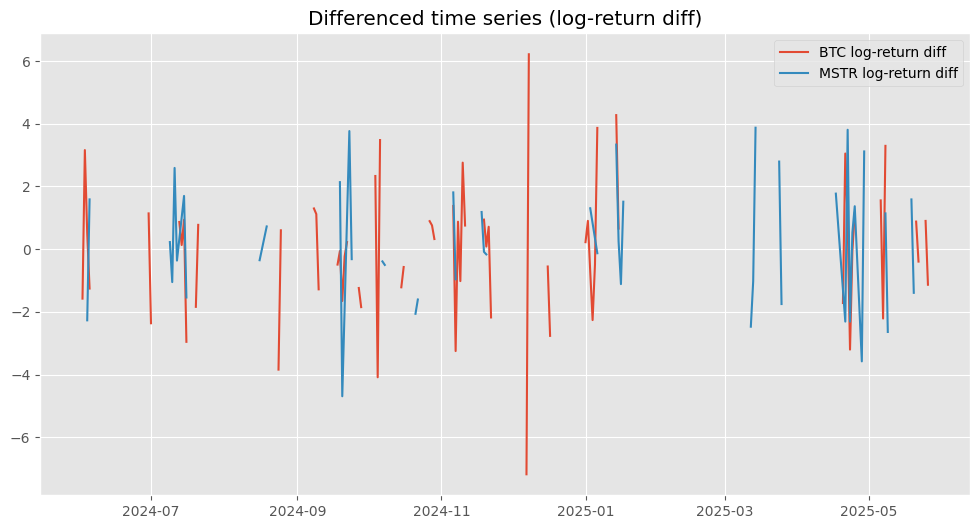

In [ ]:
btc_diff = btc_data_saved['Close'].pct_change().apply(np.log).diff()
mstr_diff = mstr_data_saved['Close'].pct_change().apply(np.log).diff()

plt.figure(figsize=(12,6))
plt.plot(btc_diff, label='BTC log-return diff')
plt.plot(mstr_diff, label='MSTR log-return diff')
plt.title('Differenced time series (log-return diff)')
plt.legend()
plt.show()

If the series is non-stationary, it becomes necessary to transform it, for example by collecting the differences of the residuals through linear regression, to make it suitable for statistical analysis and forecasting.

ENGLE-GRANGER TWO-STEP METHOD WITH OLS REGRESSION MODEL

Steps involved:

* Estimate the coefficients of the linear regression model between one stock (dependent variable) and the other stock (independent variable) using the ordinary least squares (OLS) method.
* Calculate the residuals of the linear regression model.
* Test whether the time series of residuals is stationary using a unit root test, such as the Augmented Dickey-Fuller (ADF) test.
* If the residuals are stationary, the two assets are cointegrated.

In [ ]:
import statsmodels.api as sm
import pandas as pd

# Temporal alignment between the two series on closing prices
df = pd.DataFrame({
    'BTC': btc_data_saved['Close'],
    'MSTR': mstr_data_saved['Close']
}).dropna()  # Removes any non-overlapping dates

# Normalization to bring both series to a relative scale (initial value = 1)
btc_scaled = df['BTC'] / df['BTC'].iloc[0]
mstr_scaled = df['MSTR'] / df['MSTR'].iloc[0]

# Definition of variables for linear regression with scaled data
Y = mstr_scaled  # Dependent variable (normalized MSTR)
X = btc_scaled   # Independent variable (normalized BTC)

# Add intercept (constant) to the independent variable
X_with_constant = sm.add_constant(X)

# Construction and estimation of the OLS model
model = sm.OLS(Y, X_with_constant).fit()

# Calculation of residuals (spread)
residuals = Y - model.predict(X_with_constant)

# Quick output
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MSTR   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.917
Method:                 Least Squares   F-statistic:                     2762.
Date:                Thu, 29 May 2025   Prob (F-statistic):          1.96e-136
Time:                        10:33:47   Log-Likelihood:                 79.404
No. Observations:                 250   AIC:                            -154.8
Df Residuals:                     248   BIC:                            -147.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.2130      0.055    -22.125      0.0

* R-squared: 0.918
  91.8% of the variance of the normalized MSTR price is explained by the normalized BTC price. Strong linear relationship (already confirmed by the short-term correlation).

* Prob (F-statistic): 1.96e-136
  P-value very close to zero: the model is highly significant, meaning there is a real, non-random relationship between BTC and MSTR.

* BTC Coefficient: 2.3774
  The coefficient indicates that for every one-unit percentage increase in BTC, there is an associated increase of about 2.34 relative units in MSTR. This reflects the estimated relationship between the two assets once scaled relatively.

* Durbin-Watson: 0.238
  Much lower than 2: indicates strong autocorrelation of the residuals, a factor that suggests cointegration in advance. We still analyze the residuals with an ADF stationarity test to confirm if a long-term relationship exists between the two assets despite short-term fluctuations.


RESIDUALS (SPREAD) PLOT

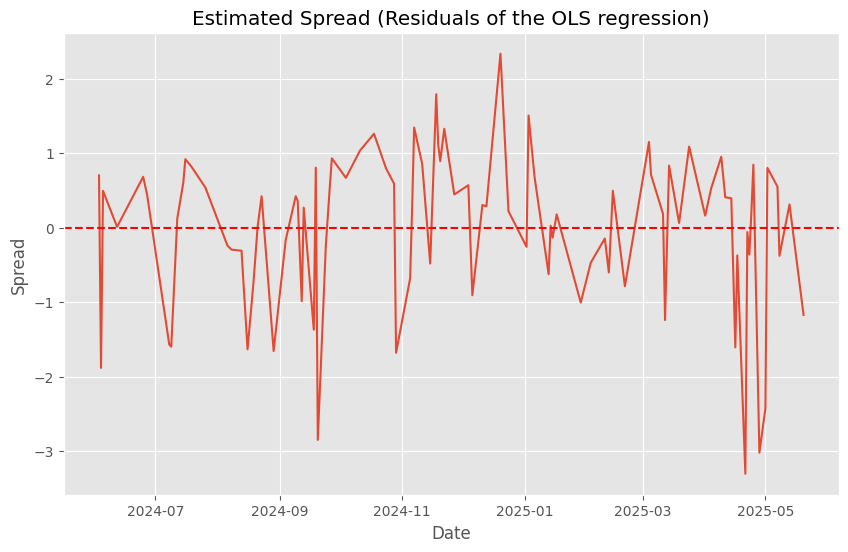

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Calculation of logarithmic returns
btc = btc_data_saved['Close'].pct_change().apply(np.log).dropna()
btc.name = 'BTC'  # Assigns the name to the Series

mstr = mstr_data_saved['Close'].pct_change().apply(np.log).dropna()
mstr.name = 'MSTR'  # Assigns the name to the Series

# Construction of the DataFrame with correct names
common_log = pd.concat([btc, mstr], axis=1).dropna()

# Regression MSTR ~ BTC
X = sm.add_constant(common_log['BTC'])
model = sm.OLS(common_log['MSTR'], X).fit()
spread = model.resid

# Plot of residuals (spread)
plt.figure(figsize=(10, 6))
plt.plot(spread)
plt.title('Estimated Spread (Residuals of the OLS regression)')
plt.xlabel('Date')
plt.ylabel('Spread')
plt.axhline(0, color='red', linestyle='--')
plt.show()


We are attempting to demonstrate the cointegration between BTC and MSTR, that is, even if the individual series move in a non-stationary manner, there exists a linear combination of the two (defined as the spread) that is stationary, oscillating around a constant mean and tending to return to it over time.

The chart visually confirms this concept:

* The residuals do not show a progressive drift (which would be a sign of non-stationarity).

* The spread oscillates around zero and shows mean reversion, despite some large temporary deviations (typical of the market).

This behavior is consistent with the hypothesis that MSTR and BTC are cointegrated: they diverge in the short term but return to an equilibrium relationship in the long term.

To formally prove cointegration, we perform the Augmented Dickey-Fuller (ADF) test on the residuals. If the test rejects the null hypothesis of non-stationarity, then we can conclude that the spread is stationary and that BTC and MSTR are cointegrated.

In [ ]:
from statsmodels.tsa.stattools import adfuller

# Stationarity test of residuals using the ADF test
adf_test = adfuller(residuals)

# Print the test results
print(f"ADF test statistic: {adf_test[0]:.4f}")
print(f"p-value: {adf_test[1]:.4f}")

# Interpretation of the ADF test
if adf_test[1] < 0.05:
    print("The two series are cointegrated.")
else:
    print("The two series are not cointegrated.")

ADF test statistic: -3.2178
p-value: 0.0190
The two series are cointegrated.


The test checks whether the residuals (the spread) are stationary, a key condition to confirm cointegration between BTC and MSTR. The p-value is below 0.05, indicating that the residuals are stationary and therefore cointegration exists.

**CONCLUSIONS**

MicroStrategy’s significant exposure to Bitcoin carries important implications both in the short and long term, as highlighted by the correlation and cointegration analysis between Bitcoin’s price and the company’s stock price.

**In the short term**, the strong correlation with Bitcoin implies that price movements of the cryptocurrency quickly influence the stock’s value. This opens the door to financial strategies based on Bitcoin’s positive momentum but also exposes MicroStrategy to the risk of sudden and significant price drops in the cryptocurrency, which could negatively and rapidly impact the company’s market value.

**In the long term**, the proven cointegration with Bitcoin indicates a structural link between the two assets that can be leveraged to plan more sophisticated risk management strategies. For example, it is possible to develop hedging plans or pairs trading strategies to manage prolonged market fluctuations, thereby protecting the company’s Bitcoin holdings and stabilizing its stock value.

In essence, the relationship between Bitcoin and MicroStrategy provides valuable tools and insights to optimize the company’s asset management and better navigate market dynamics, enhancing its ability to cope with a volatile and ever-evolving financial environment.